# Can other cities help forecast AQI?

**Team Toxic (23) · Advanced Foundations of Machine Learning**

We tested whether learning from 23 Indian donor cities helps predict daily AQI at six target stations when only 30, 90 or 180 target label dates are available for fitting.

Read top to bottom. The tables and plot below include saved outputs. To run the code yourself, open this notebook from the cloned repository in VS Code or Jupyter, using the Python environment in the [run instructions](docs/REPRODUCE.md). The live example uses the committed inputs and runs on CPU without downloading the research archive.

[IEEE report](paper/AFML_IEEE_Paper.pdf) · [Presentation](slides/AFML_Final_Presentation.pdf) · [Full run instructions](docs/REPRODUCE.md)

## 1. From CPCB workbooks to a forecast row

- **Source.** Official CPCB daily overall AQI. The dated research snapshot contains 3,820 annual Excel exports and 769,129 decoded station-day observations. Some exports were empty.
- **Preparation.** Verify original file hashes, parse the two workbook layouts and record data-quality flags. Use one station per selected city and build windows only when seven consecutive AQI inputs and the relevant labels exist.
- **Inputs.** Seven observed AQI values through the issue date, calendar features from that date and a forecast horizon of 1, 2 or 3 days. The label is the AQI on the future date.
- **Split.** Donor settings selected on 2023 donor data, with fitting through 2023. The six target cities are held out of donor training and tuning. We report 2024 separately and use 2025 as the main test.

[Official CPCB source](https://airquality.cpcb.gov.in/ccr/#/repository/aqi) · [Data provenance](docs/DATA_SOURCES.md) · [Actual data preparation code](scripts/final_data_pipeline.py#L19) · [Frozen input loader](scripts/load_research_inputs.py#L6)

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory

import pandas as pd
from IPython.display import display

from scripts.load_research_inputs import load_inputs

frozen = Path("data/frozen")
with TemporaryDirectory() as scratch:
    bundle, protocol, summary = load_inputs(frozen, scratch)

target_cities = list(bundle["targets"])
print(f"{summary['workbooks']:,} workbooks, {summary['observations']:,} decoded observations")
print(f"{bundle['donor_full'].city.nunique()} donor cities")
print("Target cities:", ", ".join(target_cities))

city = "Amaravati"
target = bundle["targets"][city]
columns = ["issue_date", "date", "horizon", *[f"x{i}" for i in range(7)], "y"]
display(target["test"][columns].head(3))

3,820 workbooks, 769,129 decoded observations
23 donor cities
Target cities: Amaravati, Guwahati, Ahmedabad, Pithampur, Ludhiana, Udaipur


,issue_date,date,horizon,x0,x1,x2,x3,x4,x5,x6,y
18408,2024-12-31,2025-01-01,1,33.0,35.0,67.0,126.0,82.0,102.0,109.0,180.0
18409,2024-12-30,2025-01-01,2,41.0,33.0,35.0,67.0,126.0,82.0,102.0,180.0
18410,2024-12-29,2025-01-01,3,61.0,41.0,33.0,35.0,67.0,126.0,82.0,180.0


## 2. What each model learns

| Approach | How it makes a prediction |
| --- | --- |
| Persistence | Repeats the latest observed AQI. This is a strong baseline in a daily series. |
| Local | Fits on the allowed target labels. The study includes simple regressors and local neural models. |
| Pooled | Fits one neural model across donor cities and applies it directly to the target. |
| Fine-tuned | Starts from that same pooled model, then updates it using the allowed target labels. |
| MAML, FOMAML and Reptile | Learn an initialization from donor-city tasks. MAML differentiates through the inner updates, FOMAML uses a first-order gradient approximation, and Reptile moves the initialization toward task-adapted weights. |

The benchmark includes GRU, LSTM, MLP, TCN and Transformer variants. Here are the relevant parts of the implementation.

| If asked to show… | Open this code |
| --- | --- |
| Seven-day input, calendar encoding and label budgets | [Feature construction and budget selection](scripts/final_model_engine.py#L205-L230) |
| Ridge, persistence and other simple controls | [Baseline implementation](scripts/final_model_engine.py#L731-L760) |
| Neural architectures | [Final deep forecaster](scripts/research_model_engine.py#L182-L230) |
| Supervised fitting | [Model fitting loop](scripts/research_model_engine.py#L353) |
| Meta-learning | [Inner updates and meta-gradient](scripts/research_model_engine.py#L436) · [Meta-learning training loop](scripts/research_model_engine.py#L489) |
| Forecast scoring | [MAE, RMSE and bias implementation](scripts/final_evaluation.py#L243) |

## 3. Run a real example on CPU

Reproduce one case from the original baseline benchmark. Fit Ridge on Amaravati's last 90 eligible label dates through 2023. Each date supplies three forecast examples, one per horizon. Use the original donor-tuned Ridge setting for seed 17 and score the next-day forecasts on 2025 observations. Compare them with persistence on the same dates.

The cell calls the original implementation and checks both errors against [the archived case scores](https://github.com/arjunsrikanthh/afml-course-project/blob/8f184132654470d36f3c7af2ddd8df8a1ef660d8/results/reference/case_metrics.csv). The Ridge setting is recorded in [the original fitting log](https://github.com/arjunsrikanthh/afml-course-project/blob/8f184132654470d36f3c7af2ddd8df8a1ef660d8/results/reference/fit_costs.csv).

In [2]:
import json

import numpy as np
from scripts.final_model_engine import _baseline, _config, select_budget

config = _config(json.loads(Path("configs/archive/reference.json").read_text()))
support = select_budget(target["adapt"], budget=90)
query = target["test"].query("horizon == 1").reset_index(drop=True)
assert support["date"].max() < query["date"].min()

ridge, *_ = _baseline("ridge_local", support, [query], 17, config, {"alpha": 100.0})
persistence, *_ = _baseline("persistence", support, [query], 17, config)

forecast = pd.DataFrame({
    "date": query["date"],
    "observed": query["y"],
    "persistence": persistence[0],
    "ridge_local": ridge[0],
})
scores = forecast[["persistence", "ridge_local"]].sub(forecast["observed"], axis=0).abs().mean()
archived_mae = pd.Series({"persistence": 17.68796992481203, "ridge_local": 18.587020033228217})
np.testing.assert_allclose(scores, archived_mae, atol=1e-4, rtol=0)

print(f"{city} | {support.date.nunique()} fit dates | {len(support)} fit rows | {len(query)} test dates")
print(f"Last fit label: {support.date.max():%Y-%m-%d} | First test label: {query.date.min():%Y-%m-%d}")
display(pd.DataFrame({"CPU rerun MAE": scores, "Archived MAE": archived_mae}).round(4))

Amaravati | 90 fit dates | 270 fit rows | 266 test dates
Last fit label: 2023-12-17 | First test label: 2025-01-01


,CPU rerun MAE,Archived MAE
persistence,17.688,17.688
ridge_local,18.587,18.587


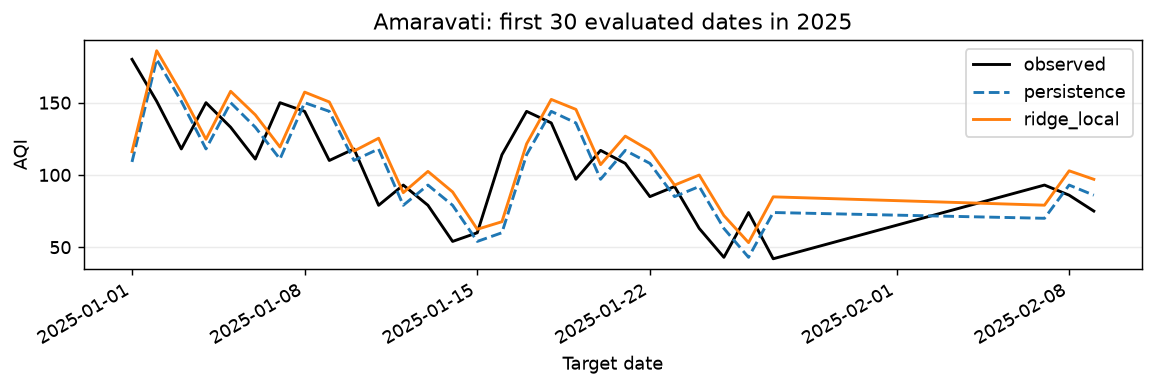

In [3]:
from io import BytesIO

import matplotlib.pyplot as plt
from IPython.display import Image

first_dates = forecast.set_index("date").iloc[:30]
ax = first_dates.plot(figsize=(9, 3.1), style=["k-", "--", "-"], linewidth=1.6)
ax.set(title="Amaravati: first 30 evaluated dates in 2025", xlabel="Target date", ylabel="AQI")
ax.grid(axis="y", alpha=0.25)
ax.figure.tight_layout()

with BytesIO() as figure:
    ax.figure.savefig(figure, format="png", dpi=130, bbox_inches="tight")
    display(Image(data=figure.getvalue(), alt="Observed AQI, persistence and Ridge forecasts for Amaravati"))
plt.close(ax.figure)

## 4. Where the full project ran

| Stage | Actual environment | Evidence |
| --- | --- | --- |
| Data preparation and exploration | Kaggle | [Executed notebook](notebooks/executed/AFML_01_Data_EDA_Executed.ipynb) · [Run receipt](evidence/execution/AFML_01_Data_EDA_Executed.receipt.json) |
| Baseline benchmark, 23 methods | Mac CPU | [Executed notebook](notebooks/executed/AFML_02_Models_Transfer_Meta_Executed.ipynb) · [Run receipt](evidence/execution/AFML_02_Models_Transfer_Meta_Executed.receipt.json) |
| Final benchmark, 33 methods including full MAML | Apple GPU using PyTorch MPS | [Executed notebook](notebooks/executed/AFML_03_Advanced_Research_Executed.ipynb) · [Run receipt](evidence/execution/AFML_03_Advanced_Research_Executed.receipt.json) |
| Combined analysis of saved predictions | Mac CPU | [Executed notebook](notebooks/executed/AFML_04_Final_Research_Synthesis_Executed.ipynb) · [Run receipt](evidence/execution/AFML_04_Final_Research_Synthesis_Executed.receipt.json) |

For full training, run `python reproduce.py train --study baseline --device cpu` or `python reproduce.py train --study final --device auto`. The expanded benchmark takes hours. To independently rescore the completed runs, use `python reproduce.py fetch`, `python reproduce.py audit` and `python reproduce.py synthesis`. [Setup and commands](docs/REPRODUCE.md)

## 5. What the full benchmark found

This section reads the comparisons from the original saved runs. Lower MAE is better.

- **Does donor pooling help?** Yes against the matching locally trained neural models, in 99 of 99 comparisons.
- **Did fine-tuning meet our original criterion?** Zero of 99 cells met the joint criterion that fine-tuning beats local training and both beat persistence on both MAE and RMSE.
- **Did meta-learning beat ordinary matched fine-tuning?** Ordinary matched GRU fine-tuning had lower MAE in all 27 primary cells across MAML, FOMAML and Reptile, three label budgets and three horizons.

[Original synthesis with detailed methodology](notebooks/executed/AFML_04_Final_Research_Synthesis_Executed.ipynb) · [Detailed output archive](results/)

In [4]:
saved = Path("results/synthesis")
checks = json.loads((saved / "synthesis_verification.json").read_text())
display(pd.DataFrame(checks["studies"])[
    ["study", "methods", "training_device", "forecasts", "independent_checks_passed"]
])

pooling = pd.read_csv(saved / "core_transfer_comparisons.csv")
pooling = pooling.query("kind == 'pooled_zero_minus_local'")
strict = pd.read_csv(saved / "original_proposal_success_conditions.csv")
meta = pd.read_csv(saved / "paired_meta_optimizer_and_donor_pool.csv")
meta = meta.query("period == 'test_2025' and kind == 'native_meta_minus_matched_transfer'")
display(pd.DataFrame([
    ["Pooling beats matching local neural model", pooling["improved"].sum(), pooling["cells"].sum()],
    ["Fine-tuning meets the strict joint criterion", strict["original_success_both_errors"].sum(), len(strict)],
    ["Matched GRU fine-tuning beats native meta-learning", (meta["delta_mae"] > 0).sum(), len(meta)],
], columns=["2025 comparison", "Cells meeting criterion", "Total cells"]))

headline = pd.read_csv(saved / "main_test_overview.csv")
display(headline.query("study == 'expanded' and budget == 90")[
    ["horizon", "lowest_MAE_method", "MAE", "best_simple_method", "best_simple_MAE"]
].round(2))

,study,methods,training_device,forecasts,independent_checks_passed
0,compact,23,cpu,1876662,9
1,expanded,33,mps,2692602,12


,2025 comparison,Cells meeting criterion,Total cells
0,Pooling beats matching local neural model,99,99
1,Fine-tuning meets the strict joint criterion,0,99
2,Matched GRU fine-tuning beats native meta-lear...,27,27


,horizon,lowest_MAE_method,MAE,best_simple_method,best_simple_MAE
12,1,deep_tcn_pooled_zero,22.33,persistence,23.12
13,2,matched_gru_finetune,27.48,mean7,29.67
14,3,deep_transformer_pooled_zero,29.85,mean7,30.91


## 6. Follow-up findings and limits

- **Fine-tuning sensitivity.** The original 100 updates worsened 2025 MAE relative to starting pooled predictions for GRU, LSTM, MLP, TCN and Transformer. A tenfold lower learning rate reduced those penalties. [Architecture comparisons](followup/extension/results/cross_architecture/)
- **MAML starting point.** With donor tasks fixed, optimizing for immediate accuracy instead of accuracy after five updates lowered zero-update MAE from 28.27 to 26.94. [MAML objective analysis](followup/extension/results/maml_objective/)
- **Interpretation.** Label scarcity is simulated by limiting fitting dates. Forecasts still use recent observed AQI. The results cover six selected station series and the follow-ups reuse the same evaluation years.

## Which files should I open?

| Location | Purpose |
| --- | --- |
| This notebook | Demo, one live rerun, and the main saved results. |
| `data/frozen/` | AQI and forecast rows, eligible stations, coverage, study rules and hashes. The loader verifies these files together. |
| `configs/` and `scripts/` | Experiment settings and Python implementation used by the notebook and command-line runs. |
| `results/` | Compact demo summaries and retraining protocols. The full exported CSVs, plots and JSONs are linked from the [archive index](results/). |
| `notebooks/` and `evidence/` | Original executed notebooks, portable full-run notebooks and run receipts. |
| `followup/` and `paper/figure_data/` | Inputs and outputs for the additional analyses and editable report. |